In [1]:
import pandas as pd

ext = pd.read_csv("../data/processed/external_features.csv")
print(ext.shape)                      # expect (2319468, 19)
print(ext.dtypes)
print(ext.isna().sum())               # gust should be ~724,562

# Checks from the handoff checklist
NATURAL_KEY = ["flight_date","reporting_airline","flight_number",
               "origin","dest","crs_dep_dt_utc"]
print("duplicate keys:", ext.duplicated(NATURAL_KEY).sum())   # expect 0

wd = pd.to_datetime(ext["weather_date"])
fd = pd.to_datetime(ext["flight_date"])
print("weather_date is always flight_date-1:", ((fd - wd).dt.days == 1).all())

print(ext["flight_date"].str[:7].value_counts().sort_index())  # 4 months only

(2319468, 19)
flight_id                    int64
flight_date                    str
reporting_airline              str
flight_number              float64
origin                         str
dest                           str
crs_dep_dt_utc                 str
dep_count_origin_1h        float64
dep_count_origin_3h        float64
arr_count_dest_1h          float64
arr_count_dest_3h          float64
total_traffic_origin_1h    float64
weather_date                   str
temp_c_prev                float64
dewp_c_prev                float64
visibility_km_prev         float64
wind_ms_prev               float64
gust_ms_prev               float64
prcp_mm_prev               float64
dtype: object
flight_id                       0
flight_date                     0
reporting_airline               0
flight_number                   1
origin                          0
dest                            0
crs_dep_dt_utc                  0
dep_count_origin_1h             0
dep_count_origin_3h             0
a

In [2]:
net = pd.read_csv("../data/processed/network_node_metrics.csv")
edges = pd.read_csv("../data/processed/network_edge_list.csv")
print(net.shape, edges.shape)         # (343, 8) and (6367, 5)
print(net.sort_values("total_strength", ascending=False).head())

(343, 8) (6367, 5)
  iata  in_degree  out_degree  in_strength  out_strength  total_strength  \
0  ATL        152         156       109884        112363          222247   
1  DFW        180         183       105096        105887          210983   
2  DEN        176         177       104114        104456          208570   
3  ORD        156         159        90558         91425          181983   
4  CLT        125         129        69777         71132          140909   

   betweenness_centrality  pagerank  
0                0.092727  0.042334  
1                0.178601  0.048106  
2                0.177478  0.046639  
3                0.105246  0.036352  
4                0.039672  0.026163  


In [3]:
pairs = pd.read_csv("../data/processed/aircraft_rotation_pairs_2024_recovered.csv", nrows=5)
print(pairs.columns.tolist())
print(pairs.head())

['incoming_row_id', 'next_row_id', 'tail_number', 'incoming_origin', 'incoming_dest', 'next_origin', 'next_dest', 'scheduled_ground_time_min', 'turnaround_slack_min', 'actual_turnaround_min', 'connection_valid', 'exclusion_reason']
   incoming_row_id  next_row_id tail_number incoming_origin incoming_dest  \
0          2795760      1799210       188NV             FLL           CVG   
1          1799210      1799211       188NV             CVG           SRQ   
2          1799211      1817693       188NV             SRQ           CVG   
3          1817693      1817691       188NV             CVG           PGD   
4          1817691      1817692       188NV             PGD           CVG   

  next_origin next_dest  scheduled_ground_time_min  turnaround_slack_min  \
0         CVG       SRQ                     5161.0                4815.0   
1         SRQ       CVG                       50.0                  56.0   
2         CVG       PGD                      957.0                 960.0   
3

In [4]:
pairs = pd.read_csv("../data/processed/aircraft_rotation_pairs_2024_recovered.csv")

print(pairs.shape)
print(pairs["connection_valid"].value_counts())
print(pairs["exclusion_reason"].value_counts(dropna=False))
print(pairs[["incoming_row_id","next_row_id"]].agg(["min","max"]))
print(pairs["scheduled_ground_time_min"].describe())
print(pairs["actual_turnaround_min"].describe())

# Do her row ids fit inside Dhanush's flight_id range?
print("max ext flight_id:", ext["flight_id"].max())
print("share of next_row_id <= that:", (pairs["next_row_id"] <= ext["flight_id"].max()).mean())

(7052817, 12)
connection_valid
True     6645970
False     406847
Name: count, dtype: int64
exclusion_reason
NaN                                                                                                                                                                                    6645970
negative_scheduled_ground_time                                                                                                                                                           72378
incoming_flight_ineligible;next_flight_ineligible;missing_incoming_scheduled_arrival;missing_next_scheduled_departure;missing_incoming_actual_arrival;missing_next_actual_departure      72141
next_flight_ineligible                                                                                                                                                                   58388
incoming_flight_ineligible;missing_incoming_actual_arrival                                                                      

In [5]:
valid = pairs[pairs["connection_valid"]]
g = valid["scheduled_ground_time_min"]
for cut in [120, 180, 360, 720, 1440]:
    print(f"ground time <= {cut:>4} min: {(g <= cut).mean():.1%} of valid pairs ({(g<=cut).sum():,})")
print("negative ground time in 'valid' rows:", (g < 0).sum())

ground time <=  120 min: 70.3% of valid pairs (4,674,468)
ground time <=  180 min: 73.2% of valid pairs (4,864,949)
ground time <=  360 min: 76.5% of valid pairs (5,081,515)
ground time <=  720 min: 93.5% of valid pairs (6,213,146)
ground time <= 1440 min: 98.2% of valid pairs (6,527,795)
negative ground time in 'valid' rows: 0


In [6]:
flights = pd.read_csv("../data/processed/flights_clean_recovered.csv")
print(flights.shape)                     # expect (7079081, ...)
print(flights.columns.tolist())

/var/folders/dm/4x_lh3dd28n335hwst5wfyth0000gn/T/ipykernel_4962/2899572509.py:1: DtypeWarning: Columns (45: cancellation_code, 78: is_diverted) have mixed types. Specify dtype option on import or set low_memory=False.
  flights = pd.read_csv("../data/processed/flights_clean_recovered.csv")


(7079081, 94)
['year', 'quarter', 'month', 'day_of_month', 'day_of_week', 'flight_date', 'reporting_airline', 'dot_id_reporting_airline', 'tail_number', 'flight_number', 'origin_airport_id', 'origin_airport_seq_id', 'origin_city_market_id', 'origin', 'origin_city_name', 'origin_state', 'origin_state_fips', 'origin_state_name', 'origin_wac', 'dest_airport_id', 'dest_airport_seq_id', 'dest_city_market_id', 'dest', 'dest_city_name', 'dest_state', 'dest_state_fips', 'dest_state_name', 'dest_wac', 'crs_dep_time', 'dep_time', 'dep_delay', 'dep_delay_minutes', 'dep_del15', 'departure_delay_groups', 'dep_time_blk', 'taxi_out', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay', 'arr_delay_minutes', 'arr_del15', 'arrival_delay_groups', 'arr_time_blk', 'cancelled', 'cancellation_code', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'flights', 'distance', 'distance_group', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay', 'first_dep_time', 'total_add_

In [7]:
cols = ["flight_date","reporting_airline","flight_number","tail_number",
        "origin","dest","crs_dep_dt_utc","arr_delay","dep_delay",
        "cancelled","diverted","rotation_eligible",
        "diversion_status_inferred_from_arrival"]
flights = pd.read_csv("../data/processed/flights_clean_recovered.csv",
                      usecols=cols, low_memory=False)
# DO NOT sort or filter 'flights'. Its row position IS the row id.
print(flights.shape)                                   # (7079081, 13)
print("index is 0..n-1:", flights.index.equals(pd.RangeIndex(len(flights))))
print("rotation_eligible rows:", flights["rotation_eligible"].sum())   # compare with 2,319,468
print(flights["flight_date"].astype(str).str[:7].value_counts().sort_index())

# Do Amulya's ids really point at the right flights?
inc = flights.iloc[pairs["incoming_row_id"].to_numpy()]
nxt = flights.iloc[pairs["next_row_id"].to_numpy()]
print("tail matches:      ", (inc["tail_number"].to_numpy() == pairs["tail_number"].to_numpy()).mean())
print("incoming dest ok:  ", (inc["dest"].to_numpy()   == pairs["incoming_dest"].to_numpy()).mean())
print("next origin ok:    ", (nxt["origin"].to_numpy() == pairs["next_origin"].to_numpy()).mean())
print("chain ok (in.dest == next.origin):", (inc["dest"].to_numpy() == nxt["origin"].to_numpy()).mean())

(7079081, 13)
index is 0..n-1: True
rotation_eligible rows: 6841162
flight_date
2024-01    547271
2024-02    519221
2024-03    591767
2024-04    582205
2024-05    609743
2024-06    611132
2024-07    634613
2024-08    619025
2024-09    582622
2024-10    615497
2024-11    575404
2024-12    590581
Name: count, dtype: int64
tail matches:       1.0
incoming dest ok:   1.0
next origin ok:     1.0
chain ok (in.dest == next.origin): 0.954627633185435


In [8]:
print(flights[["flight_date","reporting_airline","flight_number","origin","dest","crs_dep_dt_utc"]].head(3))
print(ext[["flight_date","reporting_airline","flight_number","origin","dest","crs_dep_dt_utc"]].head(3))
print(flights.dtypes[["flight_date","flight_number","crs_dep_dt_utc"]])

  flight_date reporting_airline  flight_number origin dest  \
0  2024-04-01                9E         5079.0    JFK  IND   
1  2024-04-01                9E         5112.0    MSP  XNA   
2  2024-04-01                9E         5112.0    XNA  MSP   

              crs_dep_dt_utc  
0  2024-04-01 13:30:00+00:00  
1  2024-04-01 19:20:00+00:00  
2  2024-04-01 22:03:00+00:00  
  flight_date reporting_airline  flight_number origin dest  \
0  2024-08-01                9E         4934.0    MSP  CWA   
1  2024-08-01                9E         4966.0    CVG  DTW   
2  2024-08-01                9E         5030.0    LGA  CVG   

              crs_dep_dt_utc  
0  2024-08-02 01:00:00+00:00  
1  2024-08-01 18:00:00+00:00  
2  2024-08-01 17:45:00+00:00  
flight_date           str
flight_number     float64
crs_dep_dt_utc        str
dtype: object


In [9]:
# 1. valid pairs and their incoming / next flights
valid = pairs[pairs["connection_valid"]].copy()
inc = flights.iloc[valid["incoming_row_id"].to_numpy()]
nxt = flights.iloc[valid["next_row_id"].to_numpy()]

ok = inc["dest"].to_numpy() == nxt["origin"].to_numpy()
print("valid pairs:", len(valid))
print("valid pairs with airport mismatch:", (~ok).sum(), f"({(~ok).mean():.2%})")

# 2. pair table with delays and the NEXT flight's join key
m = pd.DataFrame({
    "incoming_row_id": valid["incoming_row_id"].to_numpy(),
    "next_row_id":     valid["next_row_id"].to_numpy(),
    "tail_number":     valid["tail_number"].to_numpy(),
    "ground_min":      valid["scheduled_ground_time_min"].to_numpy(),
    "inc_arr_delay":   inc["arr_delay"].to_numpy(),
    "next_dep_delay":  nxt["dep_delay"].to_numpy(),
    "airport_ok":      ok,
})
for c in ["flight_date","reporting_airline","flight_number","origin","dest","crs_dep_dt_utc"]:
    m["next_" + c] = nxt[c].to_numpy()

# 3. step-by-step counts (this is your exclusion table for the report)
print("start:", len(m))
m = m[m["airport_ok"]];                                   print("after airport-consistent:", len(m))
m = m[m["inc_arr_delay"].notna() & m["next_dep_delay"].notna()]; print("after non-missing delays:", len(m))
m = m[m["ground_min"] <= 180];                            print("after ground <= 180:", len(m))

valid pairs: 6645970
valid pairs with airport mismatch: 112341 (1.69%)
start: 6645970
after airport-consistent: 6533629
after non-missing delays: 6533629
after ground <= 180: 4854175


In [10]:
NATURAL_KEY = ["flight_date","reporting_airline","flight_number","origin","dest","crs_dep_dt_utc"]

m4 = m[m["next_flight_date"].astype(str).str[:7].isin(["2024-01","2024-06","2024-07","2024-08"])]
print("pairs in the 4 external-feature months:", len(m4))

ext_j = ext.drop(columns=["flight_id","weather_date"])
joined = m4.merge(ext_j,
                  left_on=["next_" + c for c in NATURAL_KEY],
                  right_on=NATURAL_KEY,
                  how="left", validate="many_to_one")

assert len(joined) == len(m4), "row count changed"
joined["has_ext"] = joined["dep_count_origin_1h"].notna()
print("matched:", joined["has_ext"].sum(), f"({joined['has_ext'].mean():.1%})")
print(joined.groupby(joined["next_flight_date"].astype(str).str[:7])["has_ext"].mean())

pairs in the 4 external-feature months: 1634841
matched: 1634841 (100.0%)
next_flight_date
2024-01    1.0
2024-06    1.0
2024-07    1.0
2024-08    1.0
Name: has_ext, dtype: float64


In [11]:
bad = ~ok
print(inc[bad]["diverted"].value_counts(dropna=False))
print(inc[bad]["diversion_status_inferred_from_arrival"].value_counts(dropna=False).head())
print("same for the matching pairs:")
print(inc[~bad]["diverted"].value_counts(dropna=False))

diverted
NaN    56539
0.0    55802
Name: count, dtype: int64
diversion_status_inferred_from_arrival
True     56539
False    55802
Name: count, dtype: int64
same for the matching pairs:
diverted
NaN    4340863
0.0    2192766
Name: count, dtype: int64


In [12]:
print(joined[["inc_arr_delay","next_dep_delay","ground_min"]].describe(percentiles=[.01,.05,.5,.95,.99]))
print("pair key unique:", not joined.duplicated(["incoming_row_id","next_row_id"]).any())
print("aircraft:", joined["tail_number"].nunique())
print(joined[["inc_arr_delay","next_dep_delay"]].corr())

       inc_arr_delay  next_dep_delay    ground_min
count   1.634841e+06    1.634841e+06  1.634841e+06
mean    5.216102e+00    1.521358e+01  6.027961e+01
std     3.860553e+01    5.108725e+01  2.520080e+01
min    -8.700000e+01   -5.600000e+01  0.000000e+00
1%     -3.500000e+01   -1.400000e+01  2.400000e+01
5%     -2.600000e+01   -1.000000e+01  3.200000e+01
50%    -5.000000e+00   -1.000000e+00  5.500000e+01
95%     7.500000e+01    8.900000e+01  1.120000e+02
99%     1.660000e+02    1.990000e+02  1.580000e+02
max     1.406000e+03    1.438000e+03  1.800000e+02
pair key unique: True
aircraft: 5909
                inc_arr_delay  next_dep_delay
inc_arr_delay        1.000000        0.649078
next_dep_delay       0.649078        1.000000


In [13]:
joined.to_csv("../data/processed/modelling_table_v1.csv.gz", index=False)
print("saved:", joined.shape)

saved: (1634841, 31)


In [14]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor

df = joined.copy()
df["month"] = df["next_flight_date"].astype(str).str[5:7].astype(int)
df["dow"] = pd.to_datetime(df["next_flight_date"]).dt.dayofweek
df["dep_hour_utc"] = pd.to_datetime(df["next_crs_dep_dt_utc"], utc=True).dt.hour
df["carrier"] = df["next_reporting_airline"].astype("category").cat.codes

rng = np.random.RandomState(42)
tails = df["tail_number"].unique()
test_tails = set(rng.choice(tails, size=int(0.2 * len(tails)), replace=False))
is_test = df["tail_number"].isin(test_tails)
train, test = df[~is_test], df[is_test]
print("train:", len(train), "test:", len(test), "| aircraft in test:", len(test_tails))

/var/folders/dm/4x_lh3dd28n335hwst5wfyth0000gn/T/ipykernel_4962/1885709345.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = pd.to_datetime(df["next_flight_date"]).dt.dayofweek


train: 1302931 test: 331910 | aircraft in test: 1181


In [15]:
Y = "next_dep_delay"
core = ["inc_arr_delay", "ground_min", "month", "dow", "dep_hour_utc", "carrier"]
weather = ["temp_c_prev","dewp_c_prev","visibility_km_prev","wind_ms_prev","prcp_mm_prev"]
cong = ["dep_count_origin_1h","dep_count_origin_3h","arr_count_dest_1h",
        "arr_count_dest_3h","total_traffic_origin_1h"]

def report(name, p):
    e = test[Y].to_numpy() - p
    print(f"{name:28s} MAE {np.abs(e).mean():7.3f}   RMSE {np.sqrt((e**2).mean()):7.3f}")

preds = {}
preds["baseline_mean"] = np.full(len(test), train[Y].mean());   report("baseline (train mean)", preds["baseline_mean"])
preds["baseline_median"] = np.full(len(test), train[Y].median()); report("baseline (train median)", preds["baseline_median"])

def fit(name, feats):
    m = HistGradientBoostingRegressor(max_iter=200, random_state=42, categorical_features=["carrier"])
    m.fit(train[feats], train[Y])
    preds[name] = m.predict(test[feats]); report(name, preds[name])

fit("core", core)
fit("core+weather", core + weather)
fit("core+weather+congestion", core + weather + cong)

baseline (train mean)        MAE  25.415   RMSE  50.752
baseline (train median)      MAE  20.628   RMSE  53.246
core                         MAE  12.639   RMSE  37.337
core+weather                 MAE  12.569   RMSE  37.225
core+weather+congestion      MAE  12.531   RMSE  37.216


In [16]:
import os
os.makedirs("../results", exist_ok=True)

y = test[Y].to_numpy()
codes, uniq = pd.factorize(test["tail_number"].to_numpy())
n_air = len(uniq)
cnt = np.bincount(codes, minlength=n_air)

def per_air(p):
    e = y - p
    return np.bincount(codes, weights=np.abs(e), minlength=n_air), np.bincount(codes, weights=e**2, minlength=n_air)

stats = {k: per_air(v) for k, v in preds.items()}

B = 2000
rng = np.random.RandomState(42)
w = rng.multinomial(n_air, np.ones(n_air) / n_air, size=B)   # how often each aircraft is drawn
tot_n = w @ cnt

def boot_metric(name):
    ae, se = stats[name]
    return (w @ ae) / tot_n, np.sqrt((w @ se) / tot_n)

def point(name):
    e = y - preds[name]
    return np.abs(e).mean(), np.sqrt((e ** 2).mean())

comparisons = [
    ("baseline_median", "core"),
    ("core", "core+weather"),
    ("core+weather", "core+weather+congestion"),
    ("core", "core+weather+congestion"),
]

rows = []
for a, b in comparisons:
    (mae_a, rmse_a), (mae_b, rmse_b) = point(a), point(b)
    bm_a, br_a = boot_metric(a)
    bm_b, br_b = boot_metric(b)
    for metric, pa, pb, ba, bb in [("MAE", mae_a, mae_b, bm_a, bm_b), ("RMSE", rmse_a, rmse_b, br_a, br_b)]:
        d = ba - bb                         # positive = second model is better
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append({"from": a, "to": b, "metric": metric,
                     "improvement": pa - pb, "pct": 100 * (pa - pb) / pa,
                     "ci_low": lo, "ci_high": hi,
                     "ci_excludes_0": (lo > 0) or (hi < 0)})

res = pd.DataFrame(rows).round(4)
print(res.to_string(index=False))
res.to_csv("../results/model_comparison_bootstrap.csv", index=False)

           from                      to metric  improvement     pct  ci_low  ci_high  ci_excludes_0
baseline_median                    core    MAE       7.9891 38.7289  7.7709   8.2147           True
baseline_median                    core   RMSE      15.9086 29.8777 15.4209  16.4268           True
           core            core+weather    MAE       0.0706  0.5584  0.0552   0.0871           True
           core            core+weather   RMSE       0.1121  0.3001  0.0554   0.1755           True
   core+weather core+weather+congestion    MAE       0.0381  0.3028  0.0215   0.0539           True
   core+weather core+weather+congestion   RMSE       0.0095  0.0256 -0.0408   0.0621          False
           core core+weather+congestion    MAE       0.1086  0.8595  0.0918   0.1251           True
           core core+weather+congestion   RMSE       0.1216  0.3256  0.0618   0.1824           True


In [17]:
months4 = ["2024-01","2024-06","2024-07","2024-08"]
nd = nxt["flight_date"].astype(str).str[:7].isin(months4).to_numpy()
keep = (ok & nd & inc["arr_delay"].notna().to_numpy() & nxt["dep_delay"].notna().to_numpy()
        & (valid["scheduled_ground_time_min"].to_numpy() <= 1440))

base = pd.DataFrame({
    "tail_number":   valid["tail_number"].to_numpy()[keep],
    "ground_min":    valid["scheduled_ground_time_min"].to_numpy()[keep],
    "inc_arr_delay": inc["arr_delay"].to_numpy()[keep],
    "next_dep_delay":nxt["dep_delay"].to_numpy()[keep],
})
for c in NATURAL_KEY:
    base["next_" + c] = nxt[c].to_numpy()[keep]

n0 = len(base)
base = base.merge(ext_j, left_on=["next_" + c for c in NATURAL_KEY],
                  right_on=NATURAL_KEY, how="left", validate="many_to_one")
assert len(base) == n0

base["month"] = base["next_flight_date"].astype(str).str[5:7].astype(int)
base["dow"] = pd.to_datetime(base["next_flight_date"]).dt.day_of_week
base["dep_hour_utc"] = pd.to_datetime(base["next_crs_dep_dt_utc"], utc=True).dt.hour
base["carrier"] = base["next_reporting_airline"].astype("category").cat.codes
base["gust_reported"] = base["gust_ms_prev"].notna().astype(int)

print("rows up to 1440 min:", len(base))
print("rows at <=180 (should be 1,634,841):", (base["ground_min"] <= 180).sum())

rows up to 1440 min: 2159391
rows at <=180 (should be 1,634,841): 1634841


In [18]:
def boot_gain(te, p_a, p_b, B=1000, seed=42):
    """MAE improvement of model b over a, with a 95% CI from resampling aircraft."""
    y = te[Y].to_numpy()
    codes, u = pd.factorize(te["tail_number"].to_numpy())
    n = len(u); cnt = np.bincount(codes, minlength=n)
    ea = np.bincount(codes, weights=np.abs(y - p_a), minlength=n)
    eb = np.bincount(codes, weights=np.abs(y - p_b), minlength=n)
    w = np.random.RandomState(seed).multinomial(n, np.ones(n) / n, size=B)
    d = (w @ ea - w @ eb) / (w @ cnt)
    return (np.abs(y - p_a).mean() - np.abs(y - p_b).mean(), *np.percentile(d, [2.5, 97.5]))

def run_experiment(label, d, test_mask, feature_sets):
    tr, te = d[~test_mask], d[test_mask]
    P = {}
    for name, feats in feature_sets.items():
        mdl = HistGradientBoostingRegressor(max_iter=200, random_state=42,
                                            categorical_features=["carrier"])
        mdl.fit(tr[feats], tr[Y]); P[name] = mdl.predict(te[feats])
    yv = te[Y].to_numpy()
    row = {"experiment": label, "n_train": len(tr), "n_test": len(te)}
    for name in P:
        e = yv - P[name]
        row[name + "_MAE"] = np.abs(e).mean()
        row[name + "_RMSE"] = np.sqrt((e ** 2).mean())
    names = list(P)
    for a, b in zip(names[:-1], names[1:]):
        g, lo, hi = boot_gain(te, P[a], P[b])
        row[f"gain_{b}_vs_{a}_MAE"] = g
        row[f"ci_low_{b}"] = lo; row[f"ci_high_{b}"] = hi
    return row

FS = {"core": core, "core+weather": core + weather,
      "core+weather+congestion": core + weather + cong}
results = []

In [19]:
for cut in [120, 180, 360, 720, 1440]:
    d = base[base["ground_min"] <= cut]
    results.append(run_experiment(f"ground<={cut}", d, d["tail_number"].isin(test_tails), FS))
    print("done", cut)
pd.DataFrame(results).round(3).T

done 120
done 180
done 360
done 720
done 1440


,0,1,2,3,4
experiment,ground<=120,ground<=180,ground<=360,ground<=720,ground<=1440
n_train,1251927,1302931,1360905,1650134,1721796
n_test,319271,331910,346562,419948,437595
core_MAE,12.474,12.639,12.956,13.535,13.969
core_RMSE,36.809,37.337,38.088,38.893,39.367
core+weather_MAE,12.427,12.569,12.883,13.482,13.878
core+weather_RMSE,36.717,37.225,37.935,38.772,39.196
core+weather+congestion_MAE,12.312,12.531,12.801,13.396,13.836
core+weather+congestion_RMSE,36.638,37.216,37.858,38.683,39.187
gain_core+weather_vs_core_MAE,0.047,0.071,0.073,0.053,0.091


In [20]:
d = base[base["ground_min"] <= 180]
results.append(run_experiment("time split (test=Aug)", d, d["month"] == 8, FS))
pd.DataFrame(results).round(3).T

,0,1,2,3,4,5
experiment,ground<=120,ground<=180,ground<=360,ground<=720,ground<=1440,time split (test=Aug)
n_train,1251927,1302931,1360905,1650134,1721796,1208966
n_test,319271,331910,346562,419948,437595,425875
core_MAE,12.474,12.639,12.956,13.535,13.969,13.223
core_RMSE,36.809,37.337,38.088,38.893,39.367,36.981
core+weather_MAE,12.427,12.569,12.883,13.482,13.878,13.136
core+weather_RMSE,36.717,37.225,37.935,38.772,39.196,36.975
core+weather+congestion_MAE,12.312,12.531,12.801,13.396,13.836,13.03
core+weather+congestion_RMSE,36.638,37.216,37.858,38.683,39.187,36.867
gain_core+weather_vs_core_MAE,0.047,0.071,0.073,0.053,0.091,0.086


In [21]:
FS_gust = {"core+weather": core + weather,
           "core+weather+gust": core + weather + ["gust_ms_prev", "gust_reported"]}
d = base[base["ground_min"] <= 180]
results.append(run_experiment("gust variant", d, d["tail_number"].isin(test_tails), FS_gust))

In [22]:
q_y = train[Y].quantile(0.99); q_x = train["inc_arr_delay"].quantile(0.99)
kept = ((test[Y] <= q_y) & (test["inc_arr_delay"] <= q_x)).to_numpy()
print(f"kept {kept.sum():,} of {len(test):,} test pairs (dropped delays above {q_y:.0f} / {q_x:.0f} min)")
for name in ["baseline_median", "core", "core+weather", "core+weather+congestion"]:
    e = test[Y].to_numpy()[kept] - preds[name][kept]
    print(f"{name:26s} MAE {np.abs(e).mean():7.3f}   RMSE {np.sqrt((e**2).mean()):7.3f}")

kept 327,308 of 331,910 test pairs (dropped delays above 200 / 167 min)
baseline_median            MAE  16.762   RMSE  32.072
core                       MAE  10.600   RMSE  18.444
core+weather               MAE  10.539   RMSE  18.403
core+weather+congestion    MAE  10.494   RMSE  18.327


In [23]:
rob = pd.DataFrame(results).round(4)
rob.to_csv("../results/robustness_checks.csv", index=False)
rob.T

,0,1,2,3,4,5,6
experiment,ground<=120,ground<=180,ground<=360,ground<=720,ground<=1440,time split (test=Aug),gust variant
n_train,1251927,1302931,1360905,1650134,1721796,1208966,1302931
n_test,319271,331910,346562,419948,437595,425875,331910
core_MAE,12.4737,12.6392,12.9564,13.5346,13.9692,13.2227,NaN
core_RMSE,36.8091,37.3371,38.0881,38.8926,39.367,36.9815,NaN
core+weather_MAE,12.427,12.5686,12.8833,13.4818,13.8779,13.1364,12.5686
core+weather_RMSE,36.7165,37.225,37.9353,38.7719,39.1958,36.9746,37.225
core+weather+congestion_MAE,12.3122,12.5305,12.8014,13.3965,13.8359,13.0298,NaN
core+weather+congestion_RMSE,36.6378,37.2155,37.8584,38.6832,39.1867,36.8668,NaN
gain_core+weather_vs_core_MAE,0.0467,0.0706,0.0731,0.0528,0.0913,0.0863,NaN


In [24]:
t = test.copy()
for k in ["core", "core+weather", "core+weather+congestion"]:
    t["ae_" + k] = np.abs(t[Y].to_numpy() - preds[k])

t["severity"] = pd.cut(t["inc_arr_delay"], [-np.inf, 0, 15, 60, np.inf],
                       labels=["<=0 (early/on time)", "0-15", "15-60", ">60"])
t["weather_available"] = t[weather].notna().all(axis=1)

def summarize(by, d=t):
    g = d.groupby(by, observed=True)
    out = g[["ae_core", "ae_core+weather", "ae_core+weather+congestion"]].mean()
    out.columns = ["MAE_core", "MAE_weather", "MAE_weather_cong"]
    out["n"] = g.size()
    out["weather_gain"] = out["MAE_core"] - out["MAE_weather"]
    out["cong_gain"] = out["MAE_weather"] - out["MAE_weather_cong"]
    return out.round(3)

sub = {}
sub["month"] = summarize("month")
sub["severity"] = summarize("severity")
sub["weather_available"] = summarize("weather_available")
top = t["next_origin"].value_counts().head(15).index
sub["top15_airports"] = summarize("next_origin", t[t["next_origin"].isin(top)])

for k, v in sub.items():
    print("\n==", k); print(v)
    v.to_csv(f"../results/subgroup_{k}.csv")


== month
       MAE_core  MAE_weather  MAE_weather_cong      n  weather_gain  cong_gain
month                                                                         
1        11.971       11.796            11.817  70457         0.175     -0.021
6        12.524       12.494            12.434  86576         0.030      0.060
7        13.764       13.722            13.601  87867         0.043      0.121
8        12.158       12.104            12.124  87010         0.054     -0.020

== severity
                     MAE_core  MAE_weather  MAE_weather_cong       n  \
severity                                                               
<=0 (early/on time)    10.108       10.058            10.006  207327   
0-15                   13.062       12.958            12.937   56109   
15-60                  16.029       15.879            15.880   46671   
>60                    28.363       28.354            28.317   21803   

                     weather_gain  cong_gain  
severity               

In [25]:
t["top15"] = t["next_origin"].isin(top)
summarize("top15")

,MAE_core,MAE_weather,MAE_weather_cong,n,weather_gain,cong_gain
top15,,,,,,
False,12.732,12.718,12.458,181761,0.014,0.259
True,12.527,12.388,12.618,150149,0.139,-0.230


In [26]:
base["inc_inferred"] = inc["diversion_status_inferred_from_arrival"].to_numpy()[keep]
base["nxt_inferred"] = nxt["diversion_status_inferred_from_arrival"].to_numpy()[keep]
base["inc_div_observed"] = inc["diverted"].notna().to_numpy()[keep]
base["nxt_div_observed"] = nxt["diverted"].notna().to_numpy()[keep]

rb = base[base["ground_min"] <= 180].copy()
print(len(rb))   # expect 1,634,841
for c in ["inc_inferred", "nxt_inferred", "inc_div_observed", "nxt_div_observed"]:
    print(c, rb[c].value_counts(dropna=False).to_dict())

1634841
inc_inferred {False: 1634558, True: 283}
nxt_inferred {False: 1634841}
inc_div_observed {True: 1634558, False: 283}
nxt_div_observed {True: 1634841}


In [27]:
late = rb[rb["inc_arr_delay"] >= 15].copy()
late["recovered"] = late["next_dep_delay"] < 15
late["absorbed"] = late["inc_arr_delay"] - late["next_dep_delay"]
print(f"late incoming flights: {len(late):,} of {len(rb):,} pairs ({len(late)/len(rb):.1%})")
print(f"recovery rate: {late['recovered'].mean():.1%}")
print(late["absorbed"].describe().round(1))

# sensitivity: late threshold (rows) x recovered threshold (columns)
grid = pd.DataFrame(index=[5, 15, 30, 60], columns=[5, 15, 30], dtype=float)
nlate = {}
for L in grid.index:
    s = rb[rb["inc_arr_delay"] >= L]
    nlate[L] = len(s)
    for R in grid.columns:
        grid.loc[L, R] = (s["next_dep_delay"] < R).mean()
print((grid * 100).round(1)); print("late counts:", nlate)

# by turnaround time
late["ground_bin"] = pd.cut(late["ground_min"], [-1, 45, 60, 90, 180])
by_g = late.groupby("ground_bin", observed=True)["recovered"].agg(["mean", "size"]).round(3)
print(by_g)

late incoming flights: 348,709 of 1,634,841 pairs (21.3%)
recovery rate: 22.0%
count    348709.0
mean          0.6
std          57.3
min       -1400.0
25%          -6.0
50%           5.0
75%          16.0
max         163.0
Name: absorbed, dtype: float64
      5     15    30
5   22.9  38.5  57.2
15  11.8  22.0  41.9
30   6.3  10.2  21.4
60   3.1   4.8   7.7
late counts: {5: 512304, 15: 348709, 30: 221661, 60: 110853}
             mean    size
ground_bin               
(-1, 45]    0.078   97632
(45, 60]    0.148  113668
(60, 90]    0.296   94100
(90, 180]   0.565   43309


In [28]:
codes, u = pd.factorize(late["tail_number"].to_numpy())
n = len(u)
cnt = np.bincount(codes, minlength=n)
rec = np.bincount(codes, weights=late["recovered"].to_numpy().astype(float), minlength=n)
w = np.random.RandomState(42).multinomial(n, np.ones(n) / n, size=2000)
boot = (w @ rec) / (w @ cnt)
print("recovery rate 95% CI (aircraft bootstrap):", np.percentile(boot, [2.5, 97.5]).round(4), "| aircraft:", n)

(grid * 100).round(1).to_csv("../results/recovery_sensitivity.csv")
by_g.to_csv("../results/recovery_by_ground_time.csv")

recovery rate 95% CI (aircraft bootstrap): [0.2172 0.2231] | aircraft: 5742


In [29]:
# 1. Drop the 283 pairs with inferred incoming status
obs = late[~late["inc_inferred"].astype(bool)]
print(f"observed-only: {len(obs):,} late pairs, recovery {obs['recovered'].mean():.2%}  (all: {late['recovered'].mean():.2%})")

# 2. Aircraft-bootstrap CIs for each ground-time bin
def rate_ci(d, B=2000):
    c, u = pd.factorize(d["tail_number"].to_numpy()); n = len(u)
    cn = np.bincount(c, minlength=n)
    rc = np.bincount(c, weights=d["recovered"].to_numpy().astype(float), minlength=n)
    w = np.random.RandomState(42).multinomial(n, np.ones(n) / n, size=B)
    b = (w @ rc) / np.maximum(w @ cn, 1)
    return np.percentile(b, [2.5, 97.5])

rows = []
for g_, d in late.groupby("ground_bin", observed=True):
    lo, hi = rate_ci(d)
    rows.append({"ground_bin": str(g_), "n_late": len(d), "recovery": d["recovered"].mean(), "ci_low": lo, "ci_high": hi})
gb = pd.DataFrame(rows).round(4); print(gb)
gb.to_csv("../results/recovery_by_ground_time_ci.csv", index=False)

observed-only: 348,653 late pairs, recovery 22.01%  (all: 22.02%)
  ground_bin  n_late  recovery  ci_low  ci_high
0   (-1, 45]   97632    0.0784  0.0757   0.0811
1   (45, 60]  113668    0.1478  0.1445   0.1512
2   (60, 90]   94100    0.2958  0.2915   0.3004
3  (90, 180]   43309    0.5653  0.5602   0.5702


In [30]:
print(edges.columns.tolist())
print(edges.head(3))

['origin', 'dest', 'flight_count', 'mean_dep_delay_min', 'mean_arr_delay_min']
  origin dest  flight_count  mean_dep_delay_min  mean_arr_delay_min
0    HNL  OGG          3911               3.241               2.128
1    OGG  HNL          3909               2.551               1.886
2    LAX  SFO          3591              10.437               8.282


In [31]:
chk = edges.merge(ext.groupby(["origin","dest"]).size().rename("n_rebuilt").reset_index(),
                  on=["origin","dest"], how="outer", indicator=True)
print(chk["_merge"].value_counts())
print("count mismatches:", (chk["flight_count"] != chk["n_rebuilt"]).sum())
print("edge total:", edges["flight_count"].sum(), "| ext rows:", len(ext))

# delays: rebuild from the flights table
mo = flights["flight_date"].astype(str).str[:7].isin(["2024-01","2024-06","2024-07","2024-08"])
f4 = flights[mo & flights["rotation_eligible"].astype(bool)]
print("rotation-eligible, 4 months:", len(f4))            # expect 2,319,468
dl = (f4.groupby(["origin","dest"])
        .agg(dep=("dep_delay","mean"), arr=("arr_delay","mean")).reset_index())
c2 = edges.merge(dl, on=["origin","dest"])
print("max |dep delay diff|:", (c2["mean_dep_delay_min"] - c2["dep"]).abs().max().round(4))
print("max |arr delay diff|:", (c2["mean_arr_delay_min"] - c2["arr"]).abs().max().round(4))

_merge
both          6367
left_only        0
right_only       0
Name: count, dtype: int64
count mismatches: 0
edge total: 2319468 | ext rows: 2319468
rotation-eligible, 4 months: 2319468
max |dep delay diff|: 0.0005
max |arr delay diff|: 0.0005


In [32]:
net = net.sort_values("out_strength", ascending=False).reset_index(drop=True)
tot = net["out_strength"].sum()          # use out_strength: total_strength counts each flight twice
for k in [1, 5, 10, 20, 50]:
    print(f"top {k:>2} airports: {net['out_strength'].head(k).sum() / tot:6.1%} of departures")
cum = net["out_strength"].cumsum() / tot
print("airports needed to cover 50% of departures:", int((cum < 0.5).sum() + 1), "of", len(net))
print("airports with out_degree <= 10:", int((net["out_degree"] <= 10).sum()))

top  1 airports:   4.8% of departures
top  5 airports:  20.9% of departures
top 10 airports:  33.7% of departures
top 20 airports:  52.2% of departures
top 50 airports:  79.2% of departures
airports needed to cover 50% of departures: 19 of 343
airports with out_degree <= 10: 216


In [33]:
ap = (edges.assign(w=edges["flight_count"] * edges["mean_dep_delay_min"])
           .groupby("origin").agg(n=("flight_count", "sum"), w=("w", "sum")).reset_index())
ap["mean_dep_delay"] = ap["w"] / ap["n"]
ap = ap.merge(net, left_on="origin", right_on="iata")
big = ap[ap["n"] >= 1000]                 # skip airports with very few flights
print(len(big), "airports with >= 1,000 departures")
print(big[["mean_dep_delay","out_strength","out_degree","betweenness_centrality","pagerank"]]
        .corr(method="spearman")["mean_dep_delay"].round(3))
ap.sort_values("n", ascending=False).head(20).to_csv("../results/network_top_airports.csv", index=False)

170 airports with >= 1,000 departures
mean_dep_delay            1.000
out_strength              0.077
out_degree                0.189
betweenness_centrality    0.206
pagerank                  0.060
Name: mean_dep_delay, dtype: float64


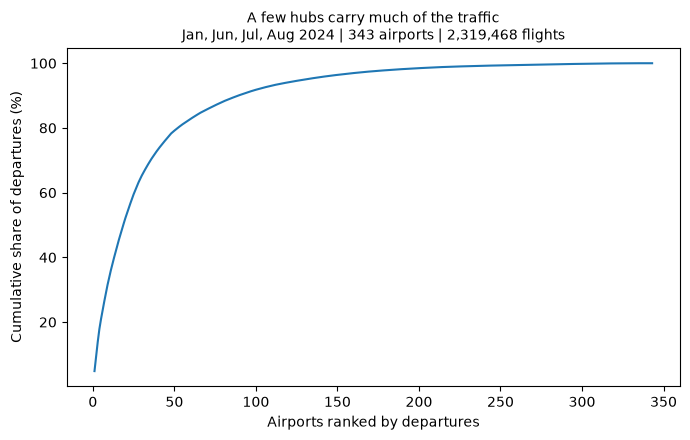

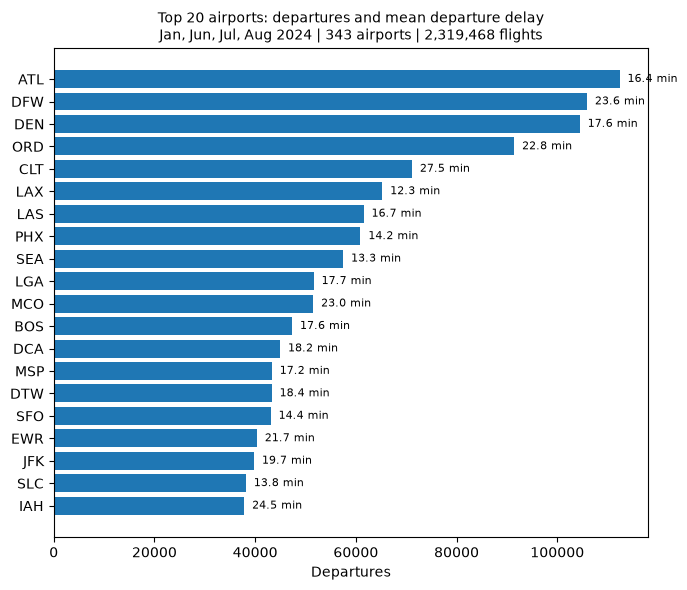

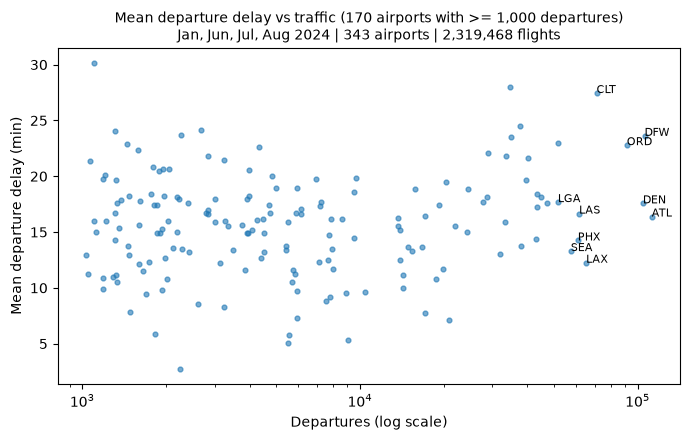

In [34]:
import matplotlib.pyplot as plt
sub = "Jan, Jun, Jul, Aug 2024 | 343 airports | 2,319,468 flights"

# 1. Hub dominance: cumulative share of departures
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, len(cum) + 1), cum * 100)
ax.set_xlabel("Airports ranked by departures"); ax.set_ylabel("Cumulative share of departures (%)")
ax.set_title("A few hubs carry much of the traffic\n" + sub, fontsize=10)
fig.tight_layout(); fig.savefig("../results/network_hub_dominance.png", dpi=200); plt.show()

# 2. Top 20 airports by departures, bar length = departures, label = mean dep delay
top20 = ap.sort_values("n", ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top20["origin"], top20["n"])
for i, (v, d) in enumerate(zip(top20["n"], top20["mean_dep_delay"])):
    ax.text(v, i, f"  {d:.1f} min", va="center", fontsize=8)
ax.set_xlabel("Departures"); ax.set_title("Top 20 airports: departures and mean departure delay\n" + sub, fontsize=10)
fig.tight_layout(); fig.savefig("../results/network_top20.png", dpi=200); plt.show()

# 3. Delay versus traffic
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(big["n"], big["mean_dep_delay"], s=12, alpha=.6)
for _, r in big.sort_values("n", ascending=False).head(10).iterrows():
    ax.annotate(r["origin"], (r["n"], r["mean_dep_delay"]), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Departures (log scale)"); ax.set_ylabel("Mean departure delay (min)")
ax.set_title(f"Mean departure delay vs traffic ({len(big)} airports with >= 1,000 departures)\n" + sub, fontsize=10)
fig.tight_layout(); fig.savefig("../results/network_delay_vs_traffic.png", dpi=200); plt.show()

In [35]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
R = "../results/"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

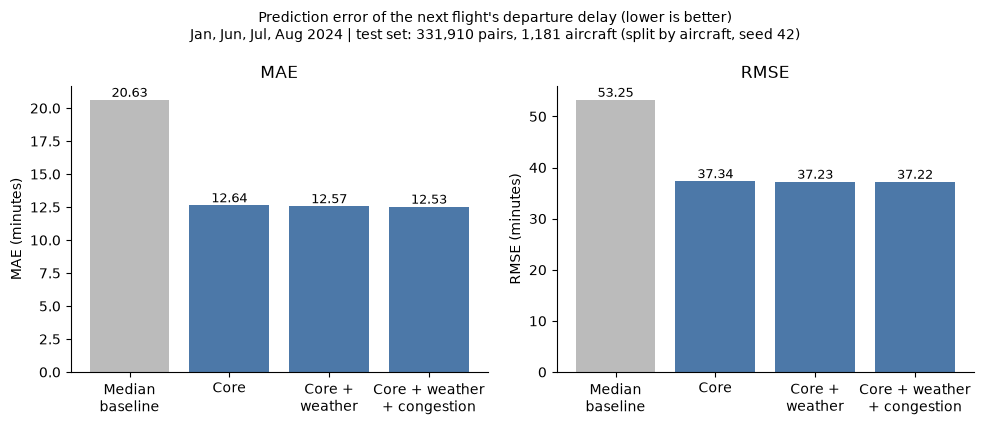

In [36]:
models = ["Median\nbaseline", "Core", "Core +\nweather", "Core + weather\n+ congestion"]
mae  = [20.628, 12.639, 12.569, 12.531]
rmse = [53.246, 37.337, 37.225, 37.216]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, vals, name in zip(axes, [mae, rmse], ["MAE (minutes)", "RMSE (minutes)"]):
    bars = ax.bar(models, vals, color=["#bbbbbb", "#4c78a8", "#4c78a8", "#4c78a8"])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_ylabel(name); ax.set_title(name.split(" ")[0])
fig.suptitle("Prediction error of the next flight's departure delay (lower is better)\n"
             "Jan, Jun, Jul, Aug 2024 | test set: 331,910 pairs, 1,181 aircraft (split by aircraft, seed 42)", fontsize=10)
fig.tight_layout(); fig.savefig(R + "fig1_model_performance.png", dpi=200); plt.show()

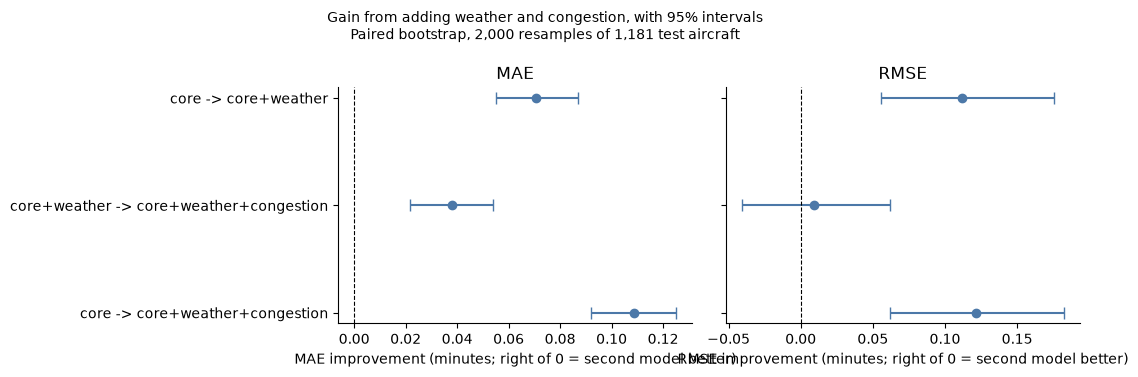

In [37]:
bt = pd.read_csv(R + "model_comparison_bootstrap.csv")
bt = bt[bt["to"] != "core"]                      # drop baseline -> core (it dwarfs the others)
bt["label"] = bt["from"] + " -> " + bt["to"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    d = bt[bt["metric"] == metric].iloc[::-1]
    ax.errorbar(d["improvement"], d["label"],
                xerr=[d["improvement"] - d["ci_low"], d["ci_high"] - d["improvement"]],
                fmt="o", capsize=4, color="#4c78a8")
    ax.axvline(0, color="k", lw=.8, ls="--")
    ax.set_xlabel(f"{metric} improvement (minutes; right of 0 = second model better)")
    ax.set_title(metric)
fig.suptitle("Gain from adding weather and congestion, with 95% intervals\n"
             "Paired bootstrap, 2,000 resamples of 1,181 test aircraft", fontsize=10)
fig.tight_layout(); fig.savefig(R + "fig2_gains_with_ci.png", dpi=200); plt.show()

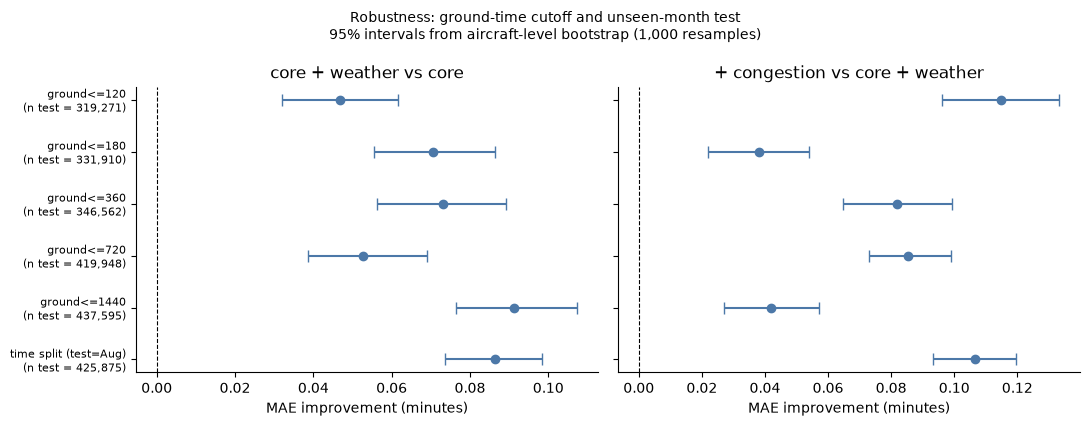

In [38]:
rb = pd.read_csv(R + "robustness_checks.csv")
rb = rb[rb["experiment"] != "gust variant"].reset_index(drop=True)
rb["lab"] = rb["experiment"] + "\n(n test = " + rb["n_test"].astype(int).map("{:,}".format) + ")"

panels = [("core + weather vs core", "gain_core+weather_vs_core_MAE", "ci_low_core+weather", "ci_high_core+weather"),
          ("+ congestion vs core + weather", "gain_core+weather+congestion_vs_core+weather_MAE",
           "ci_low_core+weather+congestion", "ci_high_core+weather+congestion")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
y = np.arange(len(rb))[::-1]
for ax, (t, g, lo, hi) in zip(axes, panels):
    ax.errorbar(rb[g], y, xerr=[rb[g] - rb[lo], rb[hi] - rb[g]], fmt="o", capsize=4, color="#4c78a8")
    ax.axvline(0, color="k", lw=.8, ls="--"); ax.set_yticks(y); ax.set_yticklabels(rb["lab"], fontsize=8)
    ax.set_xlabel("MAE improvement (minutes)"); ax.set_title(t)
fig.suptitle("Robustness: ground-time cutoff and unseen-month test\n95% intervals from aircraft-level bootstrap (1,000 resamples)", fontsize=10)
fig.tight_layout(); fig.savefig(R + "fig3_robustness.png", dpi=200); plt.show()

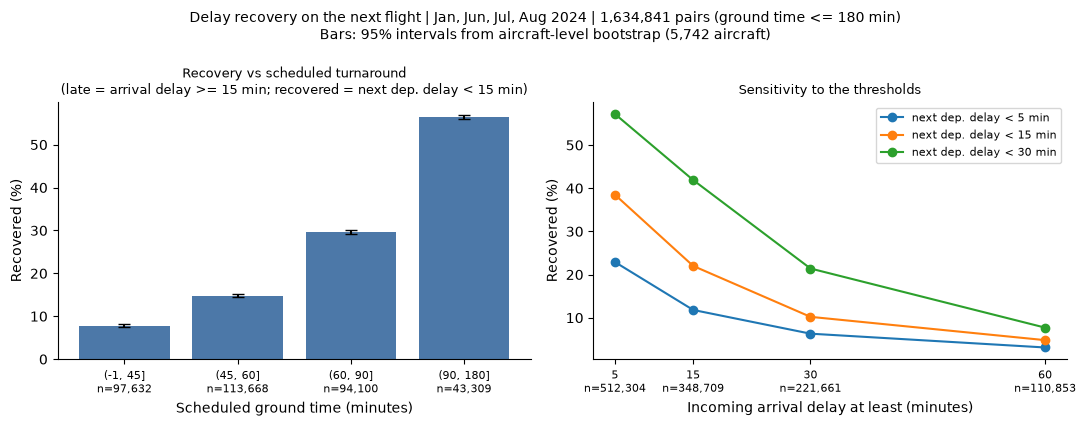

In [39]:
gb = pd.read_csv(R + "recovery_by_ground_time_ci.csv")
sens = pd.read_csv(R + "recovery_sensitivity.csv", index_col=0)
sens.columns = [int(c) for c in sens.columns]
nlate = {5: 512304, 15: 348709, 30: 221661, 60: 110853}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ax = axes[0]
x = np.arange(len(gb))
ax.bar(x, gb["recovery"] * 100, color="#4c78a8")
ax.errorbar(x, gb["recovery"] * 100,
            yerr=[(gb["recovery"] - gb["ci_low"]) * 100, (gb["ci_high"] - gb["recovery"]) * 100],
            fmt="none", ecolor="k", capsize=4)
ax.set_xticks(x); ax.set_xticklabels([f"{b}\nn={n:,}" for b, n in zip(gb["ground_bin"], gb["n_late"])], fontsize=8)
ax.set_xlabel("Scheduled ground time (minutes)"); ax.set_ylabel("Recovered (%)")
ax.set_title("Recovery vs scheduled turnaround\n(late = arrival delay >= 15 min; recovered = next dep. delay < 15 min)", fontsize=9)

ax = axes[1]
for R_ in sens.columns:
    ax.plot(sens.index, sens[R_], marker="o", label=f"next dep. delay < {R_} min")
ax.set_xticks(sens.index); ax.set_xticklabels([f"{L}\nn={nlate[L]:,}" for L in sens.index], fontsize=8)
ax.set_xlabel("Incoming arrival delay at least (minutes)"); ax.set_ylabel("Recovered (%)")
ax.set_title("Sensitivity to the thresholds", fontsize=9); ax.legend(fontsize=8)
fig.suptitle("Delay recovery on the next flight | Jan, Jun, Jul, Aug 2024 | 1,634,841 pairs (ground time <= 180 min)\n"
             "Bars: 95% intervals from aircraft-level bootstrap (5,742 aircraft)", fontsize=10)
fig.tight_layout(); fig.savefig(R + "fig4_recovery.png", dpi=200); plt.show()

In [40]:
# 1. hand spot-check: print 5 matched pairs and compare a few against the source files
chk = joined.sample(5, random_state=1)[["tail_number","next_flight_date","next_reporting_airline",
      "next_flight_number","next_origin","next_dest","next_crs_dep_dt_utc",
      "dep_count_origin_1h","temp_c_prev","inc_arr_delay","next_dep_delay"]]
print(chk.to_string())

# 2. timestamp order: incoming scheduled departure should be before the next flight's
pi = pd.to_datetime(inc["crs_dep_dt_utc"].iloc[:500000], utc=True)
pn = pd.to_datetime(nxt["crs_dep_dt_utc"].iloc[:500000], utc=True)
print("incoming departs before next:", (pi.to_numpy() < pn.to_numpy()).mean())

        tail_number next_flight_date next_reporting_airline  next_flight_number next_origin next_dest        next_crs_dep_dt_utc  dep_count_origin_1h  temp_c_prev  inc_arr_delay  next_dep_delay
767487       N553NN       2024-08-20                     OH              5285.0         SAV       CLT  2024-08-20 15:01:00+00:00                  2.0    27.444444           -7.0            -3.0
826373       N602UX       2024-08-17                     OO              5822.0         LIT       IAH  2024-08-17 22:35:00+00:00                  3.0    31.888889            7.0           -11.0
686646       N489HA       2024-08-19                     HA               307.0         KOA       HNL  2024-08-20 01:09:00+00:00                  2.0    27.611111           13.0             6.0
393880       N313DU       2024-07-02                     DL              2616.0         IAH       SLC  2024-07-02 23:59:00+00:00                 42.0    31.444444          -10.0            -1.0
1626885      N992AT       2024

In [41]:
r = joined.sample(2, random_state=1).iloc[0]
print(r[["tail_number","next_flight_date","next_origin","next_dest","next_crs_dep_dt_utc",
         "inc_arr_delay","next_dep_delay","dep_count_origin_1h","temp_c_prev"]])

# 1. the raw flights rows the pair points to
print(flights.iloc[[int(r["incoming_row_id"]), int(r["next_row_id"])]].to_string())

# 2. Dhanush's feature row for the next flight, looked up by key
k = ext[(ext["flight_date"] == r["next_flight_date"]) &
        (ext["reporting_airline"] == r["next_reporting_airline"]) &
        (ext["flight_number"] == r["next_flight_number"]) &
        (ext["origin"] == r["next_origin"]) & (ext["dest"] == r["next_dest"]) &
        (ext["crs_dep_dt_utc"] == r["next_crs_dep_dt_utc"])]
print(k.T)

tail_number                               N553NN
next_flight_date                      2024-08-20
next_origin                                  SAV
next_dest                                    CLT
next_crs_dep_dt_utc    2024-08-20 15:01:00+00:00
inc_arr_delay                               -7.0
next_dep_delay                              -3.0
dep_count_origin_1h                          2.0
temp_c_prev                            27.444444
Name: 767487, dtype: object
       flight_date reporting_airline tail_number  flight_number origin dest  dep_delay  arr_delay  cancelled  diverted             crs_dep_dt_utc  rotation_eligible  diversion_status_inferred_from_arrival
978282  2024-08-20                OH      N553NN         5050.0    CLT  SAV       -2.0       -7.0          0       0.0  2024-08-20 13:11:00+00:00               True                                   False
978283  2024-08-20                OH      N553NN         5285.0    SAV  CLT       -3.0      -11.0          0       0.0  2

In [42]:
t = pd.read_csv("../data/processed/flights_clean_recovered.csv",
                usecols=["crs_dep_dt_utc", "dep_dt_utc", "arr_dt_utc"], low_memory=False)
ia = pd.to_datetime(t["arr_dt_utc"].iloc[joined["incoming_row_id"].to_numpy()], utc=True).to_numpy()
nd = pd.to_datetime(t["dep_dt_utc"].iloc[joined["next_row_id"].to_numpy()], utc=True).to_numpy()
print("pairs checked:", len(joined))
print("incoming ACTUAL arrival <= next ACTUAL departure:", (ia <= nd).mean())

pairs checked: 1634841
incoming ACTUAL arrival <= next ACTUAL departure: 1.0
